**Projet de Machine Learning : Battre la marche aléatoire avec KNN**

**Intérêt du sujet :**

Sur les marchés financiers, il est difficile de prévoir la direction future des cours, car les variations quotidiennes comportent une forte composante aléatoire. L'objectif est de déterminer si un algorithme de Machine Learning peut exploiter les informations historiques pour améliorer la prévision de la direction du marché.

**Problématique :**

Est-ce que l'algorithme K-Nearest Neighbors (KNN), utilisant les rendements historiques et la volatilité passée du S&P 500, permet de prédire la hausse ou la baisse du marché le jour suivant avec une performance supérieure à une stratégie de référence naïve ?

**Objectif mesurable :**

Obtenir une balanced accuracy supérieure à celle de la référence naïve, avec une amélioration cible d'au moins deux points de pourcentage sur le jeu de test chronologique, jamais utilisé pendant le réglage.

**Nature du problème :**

Classification binaire :
- Classe 1 : le marché monte le jour suivant.
- Classe 0 : le marché baisse ou ne monte pas le jour suivant.




In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sys
import os

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

from sklearn.inspection import permutation_importance

GRAINE = 42
np.random.seed(GRAINE)

os.makedirs("data/raw", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Python :", sys.version)
print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)
print("Scikit-learn :", sklearn.__version__)


Python : 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas : 2.2.3
NumPy : 2.4.6
Scikit-learn : 1.6.1


  **La source utilisé:** J'utilise le S&P 500 et la source est FRED

In [4]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"

df = pd.read_csv(url)

df.to_csv(
    "data/raw/SP500.csv",
    index=False
)

print(df.head())
print(df.shape)
print(df.info())

  observation_date    SP500
0       2025-11-17  6672.41
1       2025-11-18  6617.32
2       2025-11-19  6642.16
3       2025-11-20  6538.76
4       2025-11-21  6602.99
(261, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261 entries, 0 to 260
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  261 non-null    object 
 1   SP500             251 non-null    float64
dtypes: float64(1), object(1)
memory usage: 4.2+ KB
None


**Troisième cellule Python :** nettoyage

In [ ]:
df.columns = ["Date", "SP500"]

df["Date"] = pd.to_datetime(df["Date"])

df["SP500"] = pd.to_numeric(
    df["SP500"], errors="coerce"
)

df = df.dropna()

df = df.sort_values("Date")

df = df.drop_duplicates("Date")

df = df.set_index("Date")

print(df.head())
print(df.tail())
print(df.describe())

**Quatrième cellule :** Afficher la période et le nombre d'observations

In [ ]:
print("Nombre d'observations :", len(df))

print("Date de début :", df.index.min())

print("Date de fin :", df.index.max())

print("Types des variables :")
print(df.dtypes)


**Section 03 :** Exploration des données

**Graphique 1 :** évolution du S&P 500

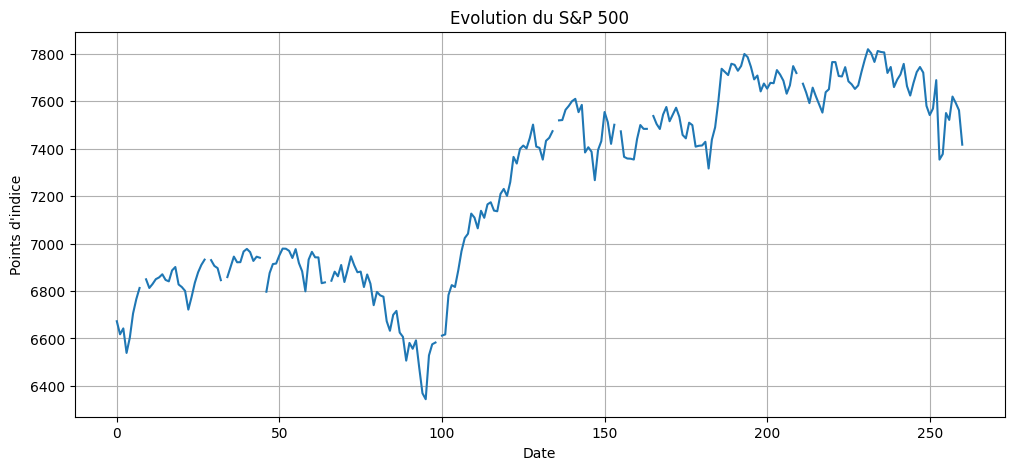

In [5]:
plt.figure(figsize=(12,5))
plt.plot(df.index, df["SP500"])
plt.title("Evolution du S&P 500")
plt.xlabel("Date")
plt.ylabel("Points d'indice")
plt.grid()
plt.show()

**Graphique 2 : **rendements quotidiens

In [ ]:
df["return"] = np.log(df["SP500"]).diff()

plt.figure(figsize=(12,5))
plt.plot(df.index, df["return"])
plt.axhline(0)
plt.title("Rendements quotidiens")
plt.xlabel("Date")
plt.ylabel("Rendement logarithmique")
plt.grid()
plt.show()

**Graphique 3 :** volatilité historique

In [ ]:
df["volatility_20"] = (
    df["return"].rolling(20).std()
)

plt.figure(figsize=(12,5))
plt.plot(df.index, df["volatility_20"])
plt.title("Volatilité historique sur 20 jours")
plt.xlabel("Date")
plt.ylabel("Ecart-type")
plt.grid()
plt.show()

In [6]:
print(df.describe())

print("Valeurs manquantes :")
print(df.isnull().sum())

print("Doublons :",
      df.index.duplicated().sum())

             SP500
count   251.000000
mean   7243.411912
std     396.670398
min    6343.720000
25%    6881.465000
50%    7365.460000
75%    7600.230000
max    7818.930000
Valeurs manquantes :
observation_date     0
SP500               10
dtype: int64
Doublons : 0


**Section 04** — Préparation des données

In [13]:
df["log_price"] = np.log(df["SP500"])

df["return"] = df["log_price"].diff()

for lag in [1, 2, 3, 5, 10, 20]:
    df[f"ret_lag_{lag}"] = (
        df["return"].shift(lag - 1)
    )

df["volatility_5"] = (
    df["return"].rolling(5).std()
)

df["volatility_20"] = (
    df["return"].rolling(20).std()
)

future_return = (
    df["log_price"].shift(-1)
    - df["log_price"]
)

df["target"] = np.where(
    future_return.isna(),
    np.nan,
    (future_return > 0).astype(int)
)

df = df.dropna()

In [ ]:
features = [
    "ret_lag_1",
    "ret_lag_2",
    "ret_lag_3",
    "ret_lag_5",
    "ret_lag_10",
    "ret_lag_20",
    "volatility_5",
    "volatility_20"
]

X = df[features]
y = df["target"].astype(int)

In [ ]:
print(y.value_counts())

print(y.value_counts(normalize=True))

**Section 05 **— Algorithme 9 : KNN

In [ ]:
pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

**Section 06 ** Protocole expérimental et apprentissage

In [ ]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline_random = DummyClassifier(
    strategy="stratified",
    random_state=GRAINE
)

baseline.fit(X_train, y_train)

baseline_random.fit(X_train, y_train)

In [ ]:
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

In [ ]:
tscv = TimeSeriesSplit(
    n_splits=5,
    gap=1
)

In [ ]:
grid = GridSearchCV(
    pipeline_knn,
    param_grid,
    cv=tscv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

In [ ]:
resultats_grid = pd.DataFrame(
    grid.cv_results_
)

colonnes = [
    "params",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]

display(
    resultats_grid[colonnes]
    .sort_values("rank_test_score")
)

**Section 07 :** Résultats et évaluation

In [14]:


# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Définir les variables explicatives
features = [
    "ret_lag_1",
    "ret_lag_2",
    "ret_lag_3",
    "ret_lag_5",
    "ret_lag_10",
    "ret_lag_20",
    "volatility_5",
    "volatility_20"
]

X = df[features]
y = df["target"].astype(int)

# 2. Séparation chronologique : 60% / 20% / 20%
n = len(df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Taille entraînement :", len(X_train))
print("Taille validation :", len(X_val))
print("Taille test :", len(X_test))

# 3. Construire le modèle KNN
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# 4. Tester différentes configurations
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

# 5. Recherche des meilleurs paramètres
tscv = TimeSeriesSplit(n_splits=5, gap=1)

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=tscv,
    scoring="balanced_accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

# 6. Meilleur modèle
best_model = grid.best_estimator_

print("\nMeilleurs paramètres :")
print(grid.best_params_)

# 7. Évaluation sur validation
y_val_pred = best_model.predict(X_val)

print("\nRésultats sur validation")
print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Balanced accuracy :", balanced_accuracy_score(y_val, y_val_pred))

# 8. Réentraînement sur train + validation
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

best_model.fit(X_train_val, y_train_val)

# 9. Évaluation finale sur test
y_test_pred = best_model.predict(X_test)

print("\nRésultats finaux sur test")
print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Balanced accuracy :", balanced_accuracy_score(y_test, y_test_pred))

print("\nRapport de classification :")
print(classification_report(y_test, y_test_pred))


Taille entraînement : 47
Taille validation : 16
Taille test : 16

Meilleurs paramètres :
{'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'distance'}

Résultats sur validation
Accuracy : 0.75
Balanced accuracy : 0.7301587301587301

Résultats finaux sur test
Accuracy : 0.4375
Balanced accuracy : 0.4375

Rapport de classification :
              precision    recall  f1-score   support

           0       0.45      0.62      0.53         8
           1       0.40      0.25      0.31         8

    accuracy                           0.44        16
   macro avg       0.43      0.44      0.42        16
weighted avg       0.43      0.44      0.42        16



/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.485      0.485      0.53       0.53       0.51       0.51
 0.58166667 0.54833333 0.54833333 0.54833333 0.53666667 0.57
 0.47333333 0.60166667 0.57       0.57              nan        nan
        nan        nan        nan        nan        nan        nan]
  warnings.warn(


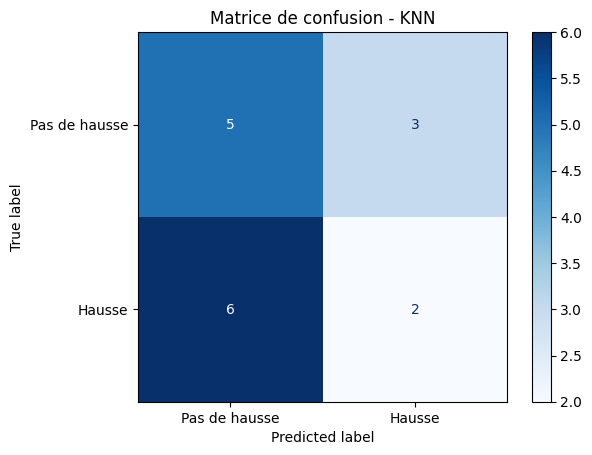

In [15]:

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pas de hausse", "Hausse"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion - KNN")
plt.show()


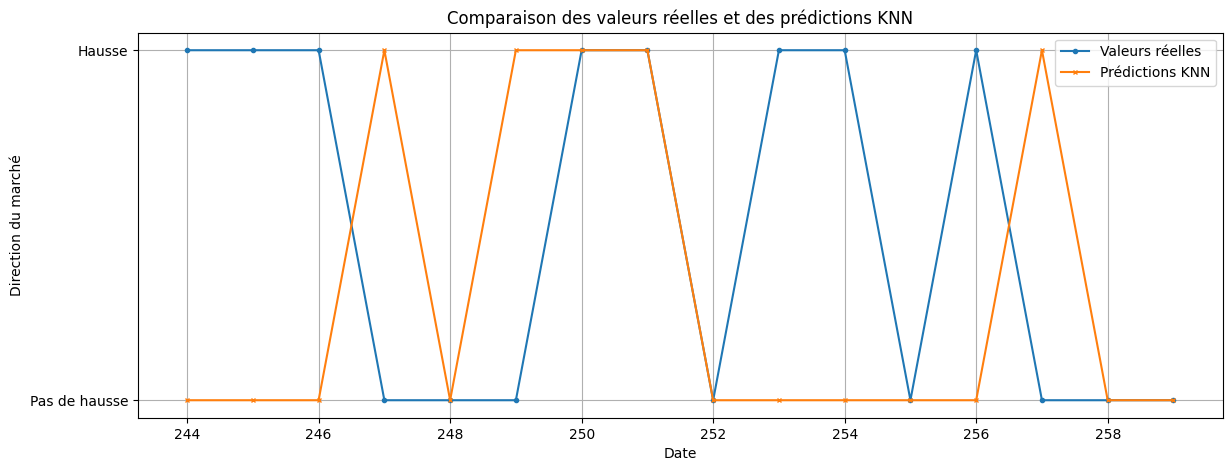

In [17]:
plt.figure(figsize=(14, 5))

# Utilisation de df.index au lieu de df["DATE"]
plt.plot(
    df.index[val_end:],
    y_test.values,
    label="Valeurs réelles",
    marker="o",
    markersize=3
)

plt.plot(
    df.index[val_end:],
    y_test_pred,
    label="Prédictions KNN",
    marker="x",
    markersize=3
)

plt.title("Comparaison des valeurs réelles et des prédictions KNN")
plt.xlabel("Date")
plt.ylabel("Direction du marché")
plt.yticks([0, 1], ["Pas de hausse", "Hausse"])
plt.legend()
plt.grid(True)
plt.show()

**Comparaison avec une prédiction naïve**

                   Modèle  Balanced Accuracy
0                     KNN             0.4375
1  Prédiction majoritaire             0.5000


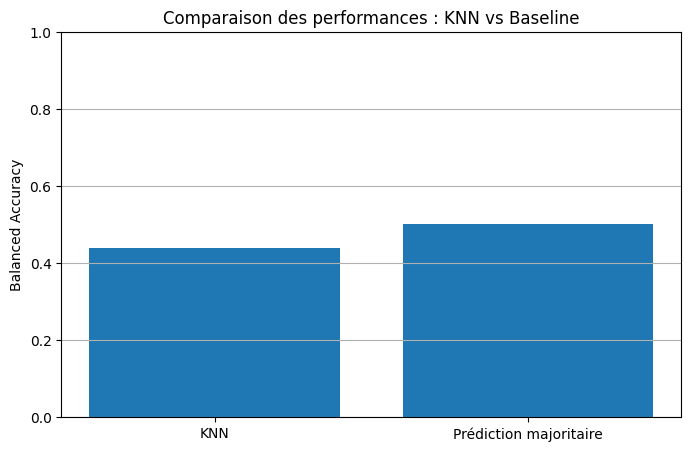

In [18]:

from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train_val, y_train_val)

y_baseline = baseline.predict(X_test)

knn_score = balanced_accuracy_score(y_test, y_test_pred)
baseline_score = balanced_accuracy_score(y_test, y_baseline)

results = pd.DataFrame({
    "Modèle": ["KNN", "Prédiction majoritaire"],
    "Balanced Accuracy": [knn_score, baseline_score]
})

print(results)

plt.figure(figsize=(8, 5))
plt.bar(results["Modèle"], results["Balanced Accuracy"])

plt.title("Comparaison des performances : KNN vs Baseline")
plt.ylabel("Balanced Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()


**Section 08 :** Analyse critique

### 08. Analyse critique

#### 8.1. Points forts de KNN

L'algorithme K-Nearest Neighbors (KNN) présente plusieurs avantages. Il est simple à comprendre et à mettre en œuvre. Il ne nécessite pas de supposer une relation linéaire entre les variables explicatives et la variable cible. Il peut ainsi identifier des relations complexes entre les rendements passés, la volatilité et la direction future du marché.

#### 8.2. Limites de KNN

Malgré ses avantages, KNN présente certaines limites. Il est sensible au choix du nombre de voisins \(k\), à la métrique de distance et à la normalisation des variables. De plus, ses performances peuvent diminuer lorsque les données sont bruitées ou lorsque les observations deviennent nombreuses. Sur les marchés financiers, les relations historiques ne garantissent pas les comportements futurs.

#### 8.3. Erreurs de classification

Le modèle cherche à prédire si le rendement du S&P 500 sera positif ou non lors de la séance suivante. Il peut commettre deux types d'erreurs : prédire une hausse alors que le marché baisse ou ne progresse pas, et prédire une absence de hausse alors que le marché progresse. Ces erreurs montrent que la direction du marché reste difficile à anticiper.

#### 8.4. Différences entre validation et test

Les performances obtenues sur les données de validation permettent de comparer les configurations de KNN et de sélectionner les paramètres du modèle. Les performances sur les données de test permettent ensuite d'évaluer sa capacité de généralisation sur des observations qui n'ont pas participé à cette sélection.

Une différence importante entre les résultats de validation et de test peut indiquer que le modèle généralise difficilement aux nouvelles données.

#### 8.5. Risque de Data Snooping

Le Data Snooping correspond au risque d'obtenir des résultats artificiellement favorables en multipliant les essais sur les mêmes données. Le test de plusieurs valeurs de k, de différentes métriques de distance ou de différentes configurations peut conduire à sélectionner un modèle adapté aux données historiques plutôt qu'à une véritable tendance généralisable.

Pour limiter ce risque, les données de test doivent rester indépendantes du processus de sélection des paramètres et être utilisées uniquement pour l'évaluation finale.

#### 8.6. Changements de régime du marché

Le marché financier peut connaître différents régimes : périodes de hausse, de baisse, de stabilité ou de forte volatilité. Les relations observées dans une période donnée peuvent ne plus être valables dans une autre période. Cette évolution constitue une difficulté supplémentaire pour KNN, qui s'appuie sur la similarité entre les observations historiques et les observations actuelles.

# Section 09 — Conclusion et références

## 9.1. Conclusion générale

Dans ce projet, nous avons étudié la possibilité de prévoir la direction du marché financier à partir des données historiques de l'indice S&P 500, en utilisant l'algorithme de classification K-Nearest Neighbors (KNN).

Les données utilisées proviennent de la plateforme FRED (Federal Reserve Economic Data). À partir des valeurs historiques du S&P 500, nous avons construit plusieurs variables explicatives, notamment les rendements logarithmiques passés et les mesures de volatilité sur différentes périodes. La variable cible permet de déterminer si l'indice connaîtra une hausse ou une absence de hausse lors de la séance suivante.

L'algorithme KNN a été choisi en raison de sa simplicité et de sa capacité à identifier des relations entre des observations similaires, sans imposer une relation linéaire entre les variables.

Une démarche expérimentale a été mise en place afin d'entraîner le modèle, de sélectionner ses meilleurs paramètres et d'évaluer ses capacités de généralisation sur des données chronologiques non utilisées pendant l'entraînement.

L'évaluation du modèle est également accompagnée d'une comparaison avec une méthode de prédiction naïve, afin d'étudier l'intérêt réel de l'utilisation de KNN.

Cependant, la prévision des marchés financiers reste une tâche complexe. Les rendements sont difficiles à anticiper, les données peuvent être bruitées et les comportements du marché peuvent évoluer au cours du temps. De plus, les performances obtenues sur les données historiques ne garantissent pas des performances similaires dans le futur.

En conclusion, ce projet permet d'étudier l'application de l'apprentissage automatique à la prévision de la direction du S&P 500 et de mieux comprendre les possibilités ainsi que les limites de l'algorithme KNN dans un contexte financier.

## 9.2. Références bibliographiques

1. **FRED – Federal Reserve Economic Data.** Série historique S&P 500 (SP500).  
   https://fred.stlouisfed.org/series/SP500

2. **Scikit-learn Documentation.** K-Nearest Neighbors Classification.  
   https://scikit-learn.org/stable/modules/neighbors.html

3. **Scikit-learn Documentation.** Model Selection and Grid Search.  
   https://scikit-learn.org/stable/modules/grid_search.html

4. **Scikit-learn Documentation.** Classification Metrics.  
   https://scikit-learn.org/stable/modules/model_evaluation.html

5. **Cours Algorithmes de Machine Learning.** Support pédagogique du cours.

6. **TP Machine Learning (TP ML).** Travaux pratiques et exercices réalisés dans le cadre du module.

*Remarque : les supports de cours et les travaux pratiques sont à compléter avec le nom de l'enseignant, l'établissement et l'année universitaire, si ces informations sont demandées.*